# Performance Engineering & Benchmark Analysis Report
## NYC TLC Yellow Taxi Analytics (ComPar 26/27)

This notebook automatically loads JSON metric files exported by `SparkProfiler` from `output/metrics/<op>/profiling_*.json` (with backward compatibility for `output/*Metrics/` and `output/benchmarks/`) and generates:
1. **Full Formatted Tables** (Wall Time, Speedup vs v0 and vs previous version, CPU, GC, I/O wait, Peak Memory, Shuffle R/W, Spill, and Task Skew), including direct export to **Markdown** and **LaTeX**.
2. **Performance Engineering Charts** (Wall Time & Speedup progression, CPU vs GC vs I/O time breakdown, Memory & Shuffle volume, and Spark Stages & Tasks count).
3. **Detailed Stage Breakdown and Task Skew Diagnosis**.


### 1. Automatic Loading of Benchmark JSONs


In [1]:
import os
import re
import glob
import json
import subprocess
import sys

# Ensure matplotlib, seaborn, and tabulate are installed in notebook environment
for pkg in ["matplotlib", "seaborn", "tabulate"]:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 200
sns.set_theme(style="whitegrid", palette="deep")

# Detect output directory whether inside Jupyter container (/output) or locally (../output / output)
BASE_OUTPUT = "/output" if os.path.exists("/output") else ("../output" if os.path.exists("../output") else "output")
PLOTS_DIR = os.path.join(BASE_OUTPUT, "plots")
os.makedirs(PLOTS_DIR, exist_ok=True)

def fmt_bytes(b):
    n = float(b)
    for unit in ["B", "KB", "MB", "GB", "TB"]:
        if abs(n) < 1024.0:
            return f"{n:.1f} {unit}"
        n /= 1024.0
    return f"{n:.1f} PB"

def natural_key(s):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", str(s))]

def load_benchmark_jsons(base_dir):
    patterns = [
        os.path.join(base_dir, "metrics", "*", "profiling_*.json"),
        os.path.join(base_dir, "metrics", "*", "*.json"),
        os.path.join(base_dir, "*Metrics", "profiling_*.json"),
        os.path.join(base_dir, "benchmarks", "profiling_*.json"),
        os.path.join(base_dir, "profiling_report.json"),
    ]
    found = []
    for pat in patterns:
        found.extend(glob.glob(pat))
    bench_files = sorted(list(set(found)), key=natural_key)

    run_rows = []
    stage_rows = []

    for fpath in bench_files:
        fname = os.path.basename(fpath)
        label = re.sub(r"^profiling_|\.json$", "", fname)
        if label == "report":
            label = "latest"

        with open(fpath, "r", encoding="utf-8") as f:
            data = json.load(f)

        for op_name, m in data.items():
            exec_run_s = m.get("executorRunTimeMs", 0) / 1000.0
            exec_cpu_s = m.get("executorCpuTimeMs", 0) / 1000.0
            gc_s = m.get("jvmGcTimeMs", 0) / 1000.0
            io_wait_s = max(0.0, exec_run_s - exec_cpu_s - gc_s)
            cpu_eff_pct = (exec_cpu_s / exec_run_s * 100.0) if exec_run_s > 0 else 0.0

            run_rows.append({
                "file": fname,
                "version": label,
                "operation": op_name,
                "wall_time_s": m.get("wallTimeS", 0.0),
                "num_jobs": m.get("numJobs", 0),
                "num_stages": m.get("numStages", 0),
                "num_tasks": m.get("numTasks", 0),
                "exec_run_s": exec_run_s,
                "exec_cpu_s": exec_cpu_s,
                "jvm_gc_s": gc_s,
                "io_wait_s": io_wait_s,
                "cpu_efficiency_pct": cpu_eff_pct,
                "peak_mem_bytes": m.get("peakExecutionMemoryBytes", 0),
                "peak_mem_mb": m.get("peakExecutionMemoryBytes", 0) / (1024.0 ** 2),
                "input_bytes": m.get("inputBytes", 0),
                "output_bytes": m.get("outputBytes", 0),
                "shuffle_read_bytes": m.get("shuffleReadBytes", 0),
                "shuffle_write_bytes": m.get("shuffleWriteBytes", 0),
                "total_shuffle_mb": (m.get("shuffleReadBytes", 0) + m.get("shuffleWriteBytes", 0)) / (1024.0 ** 2),
                "mem_spill_bytes": m.get("memorySpilledBytes", 0),
                "disk_spill_bytes": m.get("diskSpilledBytes", 0),
                "median_task_ms": m.get("medianTaskDurationMs", 0),
                "max_task_ms": m.get("maxTaskDurationMs", 0),
                "skew_ratio": m.get("skewRatio", 1.0)
            })

            for st in m.get("stages", []):
                stage_rows.append({
                    "version": label,
                    "operation": op_name,
                    "stage_id": st.get("stageId", -1),
                    "stage_name": re.sub(r"<[^>]+>", " ", st.get("name", ""))[:45],
                    "num_tasks": st.get("numTasks", 0),
                    "run_time_ms": st.get("executorRunTimeMs", 0),
                    "cpu_time_ms": st.get("executorCpuTimeMs", 0),
                    "gc_time_ms": st.get("jvmGcTimeMs", 0),
                    "peak_mem_mb": st.get("peakExecutionMemoryBytes", 0) / (1024.0 ** 2),
                    "shuffle_read_kb": st.get("shuffleReadBytes", 0) / 1024.0,
                    "shuffle_write_kb": st.get("shuffleWriteBytes", 0) / 1024.0,
                    "med_task_ms": st.get("medianTaskDurationMs", 0),
                    "max_task_ms": st.get("maxTaskDurationMs", 0),
                    "skew_ratio": st.get("skewRatio", 1.0),
                    "skew_warning": st.get("hasSignificantSkew", False)
                })

    return pd.DataFrame(run_rows), pd.DataFrame(stage_rows), bench_files

df_runs, df_stages, loaded_files = load_benchmark_jsons(BASE_OUTPUT)
print(f"Loaded JSON benchmark files ({len(loaded_files)}): {[os.path.basename(f) for f in loaded_files]}")
print(f"Operations detected: {df_runs['operation'].unique().tolist() if not df_runs.empty else 'None'}")


Loaded JSON benchmark files (31): ['profiling_v0.json', 'profiling_v1.json', 'profiling_v2.json', 'profiling_v3.json', 'profiling_v0.json', 'profiling_v1.json', 'profiling_v2.json', 'profiling_v3.json', 'profiling_v4.json', 'profiling_v5.json', 'profiling_v6.json', 'profiling_v7.json', 'profiling_v0.json', 'profiling_v1.json', 'profiling_v2.json', 'profiling_v3.json', 'profiling_v0.json', 'profiling_v1.json', 'profiling_v2.json', 'profiling_v3.json', 'profiling_v4.json', 'profiling_v5.json', 'profiling_v6.json', 'profiling_v7.json', 'profiling_v0.json', 'profiling_v1.json', 'profiling_v2.json', 'profiling_v3.json', 'profiling_v4.json', 'profiling_v5.json', 'profiling_v6.json']
Operations detected: ['M1_ingestion_and_cleaning', 'M2_temporal_demand', 'M3_zone_statistics', 'O1_fare_anomaly_detection', 'O4_trip_type_classification']


### 2. Formatted Comparative Tables (Styled HTML + Markdown + LaTeX)

Generates a summary table for each analyzed operation, computing **Speedup** (vs baseline and vs previous version) and **Time Saved (%)**.


In [2]:
def build_formatted_table(df_op):
    df_op = df_op.copy().reset_index(drop=True)
    base_wall = df_op.loc[0, "wall_time_s"] if len(df_op) > 0 and df_op.loc[0, "wall_time_s"] > 0 else 1.0

    df_op["speedup_v0"] = base_wall / df_op["wall_time_s"].replace(0, np.nan)
    prev_wall = df_op["wall_time_s"].shift(1)
    df_op["speedup_prev"] = prev_wall / df_op["wall_time_s"].replace(0, np.nan)
    df_op["time_saved_pct"] = (1.0 - df_op["wall_time_s"] / base_wall) * 100.0

    summary = pd.DataFrame({
        "Version": df_op["version"],
        "Wall Time (s)": df_op["wall_time_s"].map(lambda x: f"{x:.2f}s"),
        "vs v0": df_op["speedup_v0"].map(lambda x: f"{x:.2f}x"),
        "vs prev": df_op["speedup_prev"].map(lambda x: f"{x:.2f}x" if pd.notna(x) else "—"),
        "Delta (%)": df_op["time_saved_pct"].map(lambda x: f"{-x:+.1f}%" if abs(x) > 0.01 else "baseline"),
        "Stages": df_op["num_stages"],
        "Tasks": df_op["num_tasks"],
        "Exec Run (s)": df_op["exec_run_s"].map(lambda x: f"{x:.2f}s"),
        "CPU Time (s)": df_op["exec_cpu_s"].map(lambda x: f"{x:.2f}s"),
        "CPU Eff (%)": df_op["cpu_efficiency_pct"].map(lambda x: f"{x:.1f}%"),
        "GC Time (s)": df_op["jvm_gc_s"].map(lambda x: f"{x:.2f}s"),
        "Peak Mem": df_op["peak_mem_bytes"].map(fmt_bytes),
        "Shuffle R": df_op["shuffle_read_bytes"].map(fmt_bytes),
        "Shuffle W": df_op["shuffle_write_bytes"].map(fmt_bytes),
        "Disk Spill": df_op["disk_spill_bytes"].map(fmt_bytes),
        "Task Skew": df_op["skew_ratio"].map(lambda x: f"{x:.1f}x")
    })
    return summary, df_op

if not df_runs.empty:
    for op_name, group in df_runs.groupby("operation", sort=False):
        display(Markdown(f"### Operation: `{op_name}`"))
        summary_tbl, numeric_df = build_formatted_table(group)
        display(summary_tbl)

        print("\n--- Markdown Table (ready for report) ---")
        print(summary_tbl.to_markdown(index=False))

        print("\n--- LaTeX Table Code (ready for report.tex) ---")
        latex_cols = ["Version", "Wall Time (s)", "vs v0", "vs prev", "Stages", "Tasks", "CPU Time (s)", "GC Time (s)", "Peak Mem", "Shuffle R", "Shuffle W"]
        latex_sub = summary_tbl[[c for c in latex_cols if c in summary_tbl.columns]]
        print(latex_sub.to_latex(index=False))
        print("\n" + "=" * 90 + "\n")


### Operation: `M1_ingestion_and_cleaning`

,Version,Wall Time (s),vs v0,vs prev,Delta (%),Stages,Tasks,Exec Run (s),CPU Time (s),CPU Eff (%),GC Time (s),Peak Mem,Shuffle R,Shuffle W,Disk Spill,Task Skew
0,v0,11.37s,1.00x,—,baseline,10,28,10.67s,7.52s,70.5%,0.44s,32.2 MB,547.0 B,547.0 B,0.0 B,7.7x
1,v1,7.05s,1.61x,1.61x,-38.0%,4,10,6.49s,4.00s,61.6%,0.20s,32.2 MB,99.0 B,99.0 B,0.0 B,3.3x
2,v2,6.61s,1.72x,1.07x,-41.9%,4,10,5.88s,3.56s,60.6%,0.16s,32.2 MB,1.7 KB,1.7 KB,0.0 B,3.2x
3,v3,6.71s,1.69x,0.99x,-41.0%,5,11,5.66s,3.54s,62.6%,0.17s,32.2 MB,1.7 KB,1.7 KB,0.0 B,3.1x
4,v0,6.67s,1.70x,1.01x,-41.3%,5,11,5.80s,3.65s,62.9%,0.21s,32.2 MB,1.7 KB,1.7 KB,0.0 B,3.4x
5,v1,6.46s,1.76x,1.03x,-43.2%,5,11,5.42s,3.33s,61.4%,0.23s,32.2 MB,1.7 KB,1.7 KB,0.0 B,3.8x
6,v2,7.01s,1.62x,0.92x,-38.3%,5,11,5.95s,3.67s,61.6%,0.19s,32.2 MB,1.7 KB,1.7 KB,0.0 B,3.5x
7,v3,6.60s,1.72x,1.06x,-42.0%,5,11,5.69s,3.50s,61.4%,0.18s,32.2 MB,1.7 KB,1.7 KB,0.0 B,3.6x
8,v4,6.42s,1.77x,1.03x,-43.5%,5,11,6.13s,3.75s,61.2%,0.24s,32.2 MB,1.7 KB,1.7 KB,0.0 B,2.7x
9,v5,6.96s,1.63x,0.92x,-38.8%,5,11,6.10s,3.77s,61.8%,0.23s,32.2 MB,1.7 KB,1.7 KB,0.0 B,3.5x



--- Markdown Table (ready for report) ---
| Version   | Wall Time (s)   | vs v0   | vs prev   | Delta (%)   |   Stages |   Tasks | Exec Run (s)   | CPU Time (s)   | CPU Eff (%)   | GC Time (s)   | Peak Mem   | Shuffle R   | Shuffle W   | Disk Spill   | Task Skew   |
|:----------|:----------------|:--------|:----------|:------------|---------:|--------:|:---------------|:---------------|:--------------|:--------------|:-----------|:------------|:------------|:-------------|:------------|
| v0        | 11.37s          | 1.00x   | —         | baseline    |       10 |      28 | 10.67s         | 7.52s          | 70.5%         | 0.44s         | 32.2 MB    | 547.0 B     | 547.0 B     | 0.0 B        | 7.7x        |
| v1        | 7.05s           | 1.61x   | 1.61x     | -38.0%      |        4 |      10 | 6.49s          | 4.00s          | 61.6%         | 0.20s         | 32.2 MB    | 99.0 B      | 99.0 B      | 0.0 B        | 3.3x        |
| v2        | 6.61s           | 1.72x   | 1.07x     | -41

### Operation: `M2_temporal_demand`

,Version,Wall Time (s),vs v0,vs prev,Delta (%),Stages,Tasks,Exec Run (s),CPU Time (s),CPU Eff (%),GC Time (s),Peak Mem,Shuffle R,Shuffle W,Disk Spill,Task Skew
0,v0,5.93s,1.00x,—,baseline,11,23,5.71s,4.47s,78.4%,0.22s,289.0 MB,161.3 KB,103.3 KB,0.0 B,7.8x
1,v1,6.33s,0.94x,0.94x,+6.7%,11,23,5.80s,4.69s,80.9%,0.11s,289.0 MB,161.3 KB,103.3 KB,0.0 B,11.2x
2,v2,6.13s,0.97x,1.03x,+3.4%,9,18,5.71s,4.50s,78.8%,0.13s,289.0 MB,87.1 KB,87.1 KB,0.0 B,9.0x
3,v3,6.10s,0.97x,1.00x,+2.9%,13,25,5.69s,4.57s,80.2%,0.13s,129.3 MB,832.4 KB,832.4 KB,0.0 B,10.9x
4,v4,6.18s,0.96x,0.99x,+4.2%,9,18,5.44s,4.44s,81.6%,0.12s,32.2 MB,75.0 KB,75.0 KB,0.0 B,13.3x
5,v5,5.81s,1.02x,1.06x,-2.0%,9,18,5.29s,4.39s,83.0%,0.11s,32.2 MB,73.7 KB,73.7 KB,0.0 B,13.7x
6,v6,5.59s,1.06x,1.04x,-5.7%,6,12,5.18s,4.19s,80.9%,0.27s,64.3 MB,43.7 KB,43.7 KB,0.0 B,12.6x
7,v7,5.77s,1.03x,0.97x,-2.7%,5,11,5.46s,4.41s,80.6%,0.12s,64.3 MB,43.7 KB,43.7 KB,0.0 B,13.2x



--- Markdown Table (ready for report) ---
| Version   | Wall Time (s)   | vs v0   | vs prev   | Delta (%)   |   Stages |   Tasks | Exec Run (s)   | CPU Time (s)   | CPU Eff (%)   | GC Time (s)   | Peak Mem   | Shuffle R   | Shuffle W   | Disk Spill   | Task Skew   |
|:----------|:----------------|:--------|:----------|:------------|---------:|--------:|:---------------|:---------------|:--------------|:--------------|:-----------|:------------|:------------|:-------------|:------------|
| v0        | 5.93s           | 1.00x   | —         | baseline    |       11 |      23 | 5.71s          | 4.47s          | 78.4%         | 0.22s         | 289.0 MB   | 161.3 KB    | 103.3 KB    | 0.0 B        | 7.8x        |
| v1        | 6.33s           | 0.94x   | 0.94x     | +6.7%       |       11 |      23 | 5.80s          | 4.69s          | 80.9%         | 0.11s         | 289.0 MB   | 161.3 KB    | 103.3 KB    | 0.0 B        | 11.2x       |
| v2        | 6.13s           | 0.97x   | 1.03x     | +3.

... (5 outputs left out)


--- Markdown Table (ready for report) ---
| Version   | Wall Time (s)   | vs v0   | vs prev   | Delta (%)   |   Stages |   Tasks | Exec Run (s)   | CPU Time (s)   | CPU Eff (%)   | GC Time (s)   | Peak Mem   | Shuffle R   | Shuffle W   | Disk Spill   | Task Skew   |
|:----------|:----------------|:--------|:----------|:------------|---------:|--------:|:---------------|:---------------|:--------------|:--------------|:-----------|:------------|:------------|:-------------|:------------|
| v0        | 14.40s          | 1.00x   | —         | baseline    |       16 |      43 | 20.67s         | 15.41s         | 74.6%         | 0.35s         | 1.5 GB     | 130.2 MB    | 130.2 MB    | 0.0 B        | 25.6x       |
| v1        | 12.26s          | 1.17x   | 1.17x     | -14.9%      |       16 |      43 | 16.36s         | 12.92s         | 79.0%         | 0.29s         | 1.5 GB     | 130.2 MB    | 130.2 MB    | 0.0 B        | 16.9x       |
| v2        | 12.34s          | 1.17x   | 0.99x     | -14

### Operation: `O4_trip_type_classification`

,Version,Wall Time (s),vs v0,vs prev,Delta (%),Stages,Tasks,Exec Run (s),CPU Time (s),CPU Eff (%),GC Time (s),Peak Mem,Shuffle R,Shuffle W,Disk Spill,Task Skew
0,v0,12.61s,1.00x,—,baseline,18,51,15.66s,13.13s,83.9%,0.52s,130.0 MB,155.9 MB,155.9 MB,0.0 B,46.0x
1,v1,12.14s,1.04x,1.04x,-3.7%,18,51,15.38s,13.10s,85.2%,0.35s,130.0 MB,140.5 MB,140.5 MB,0.0 B,45.3x
2,v2,11.04s,1.14x,1.10x,-12.5%,13,31,10.77s,9.03s,83.9%,0.22s,130.0 MB,148.5 KB,147.9 KB,0.0 B,22.2x
3,v3,8.68s,1.45x,1.27x,-31.2%,13,31,8.23s,6.72s,81.6%,0.20s,257.3 MB,131.8 KB,131.2 KB,0.0 B,11.5x
4,v4,8.53s,1.48x,1.02x,-32.4%,13,31,8.07s,6.41s,79.5%,0.23s,32.2 MB,112.3 KB,111.7 KB,0.0 B,12.3x
5,v5,13.01s,0.97x,0.66x,+3.2%,22,1439,12.07s,8.03s,66.5%,0.38s,6.3 GB,818.0 KB,741.4 KB,0.0 B,11.0x
6,v6,5.02s,2.51x,2.59x,-60.2%,6,12,4.70s,3.90s,82.8%,0.08s,32.2 MB,293.2 KB,293.2 KB,0.0 B,12.0x



--- Markdown Table (ready for report) ---
| Version   | Wall Time (s)   | vs v0   | vs prev   | Delta (%)   |   Stages |   Tasks | Exec Run (s)   | CPU Time (s)   | CPU Eff (%)   | GC Time (s)   | Peak Mem   | Shuffle R   | Shuffle W   | Disk Spill   | Task Skew   |
|:----------|:----------------|:--------|:----------|:------------|---------:|--------:|:---------------|:---------------|:--------------|:--------------|:-----------|:------------|:------------|:-------------|:------------|
| v0        | 12.61s          | 1.00x   | —         | baseline    |       18 |      51 | 15.66s         | 13.13s         | 83.9%         | 0.52s         | 130.0 MB   | 155.9 MB    | 155.9 MB    | 0.0 B        | 46.0x       |
| v1        | 12.14s          | 1.04x   | 1.04x     | -3.7%       |       18 |      51 | 15.38s         | 13.10s         | 85.2%         | 0.35s         | 130.0 MB   | 140.5 MB    | 140.5 MB    | 0.0 B        | 45.3x       |
| v2        | 11.04s          | 1.14x   | 1.10x     | -12

### 3. Performance Engineering Charts (Version Comparison)

Visualizes the impact of each optimization:
1. **Wall Time (s) & Speedup Curve**
2. **Execution Time Breakdown (CPU vs I/O & Wait vs JVM GC)**
3. **Peak Execution Memory (MB) vs Total Shuffle Volume (MB)**
4. **Number of Spark Stages & Tasks**


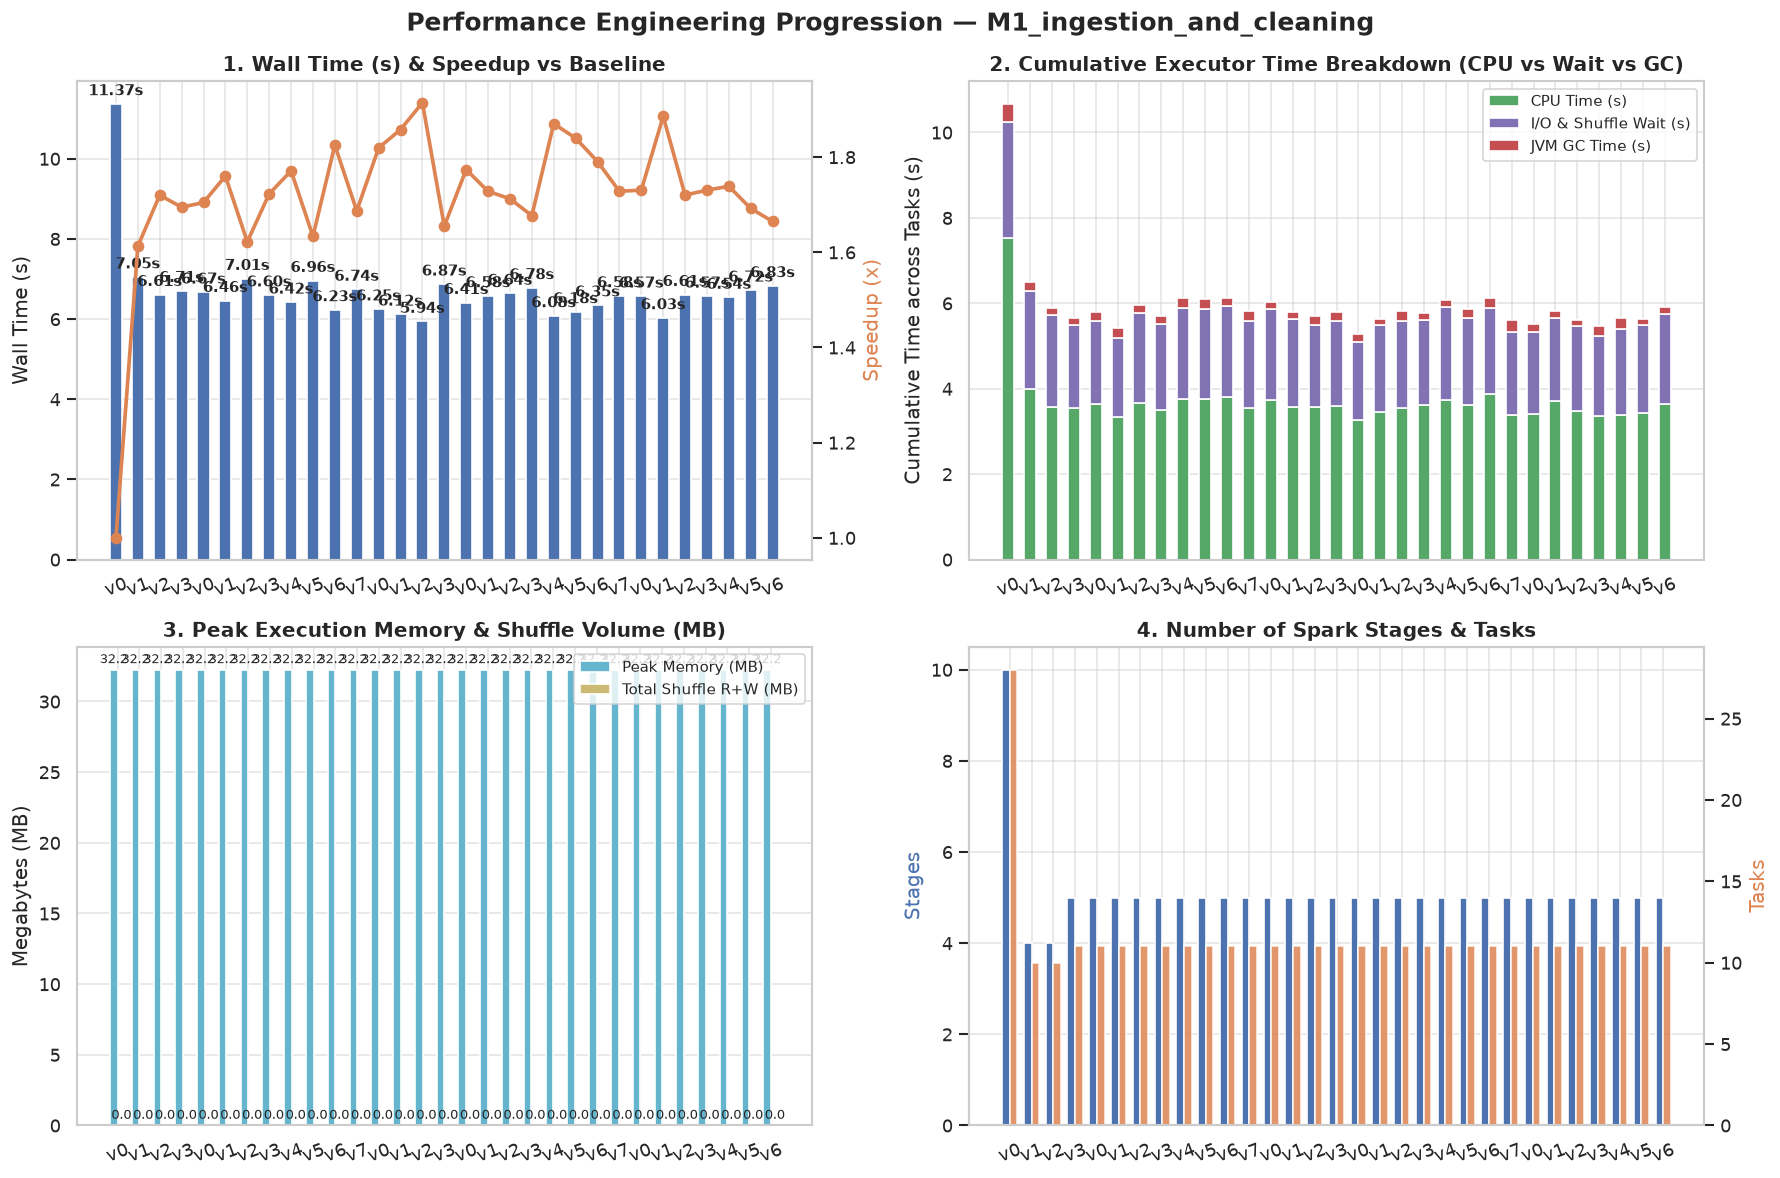

Chart saved to: ../output/plots/benchmark_M1_ingestion_and_cleaning.png


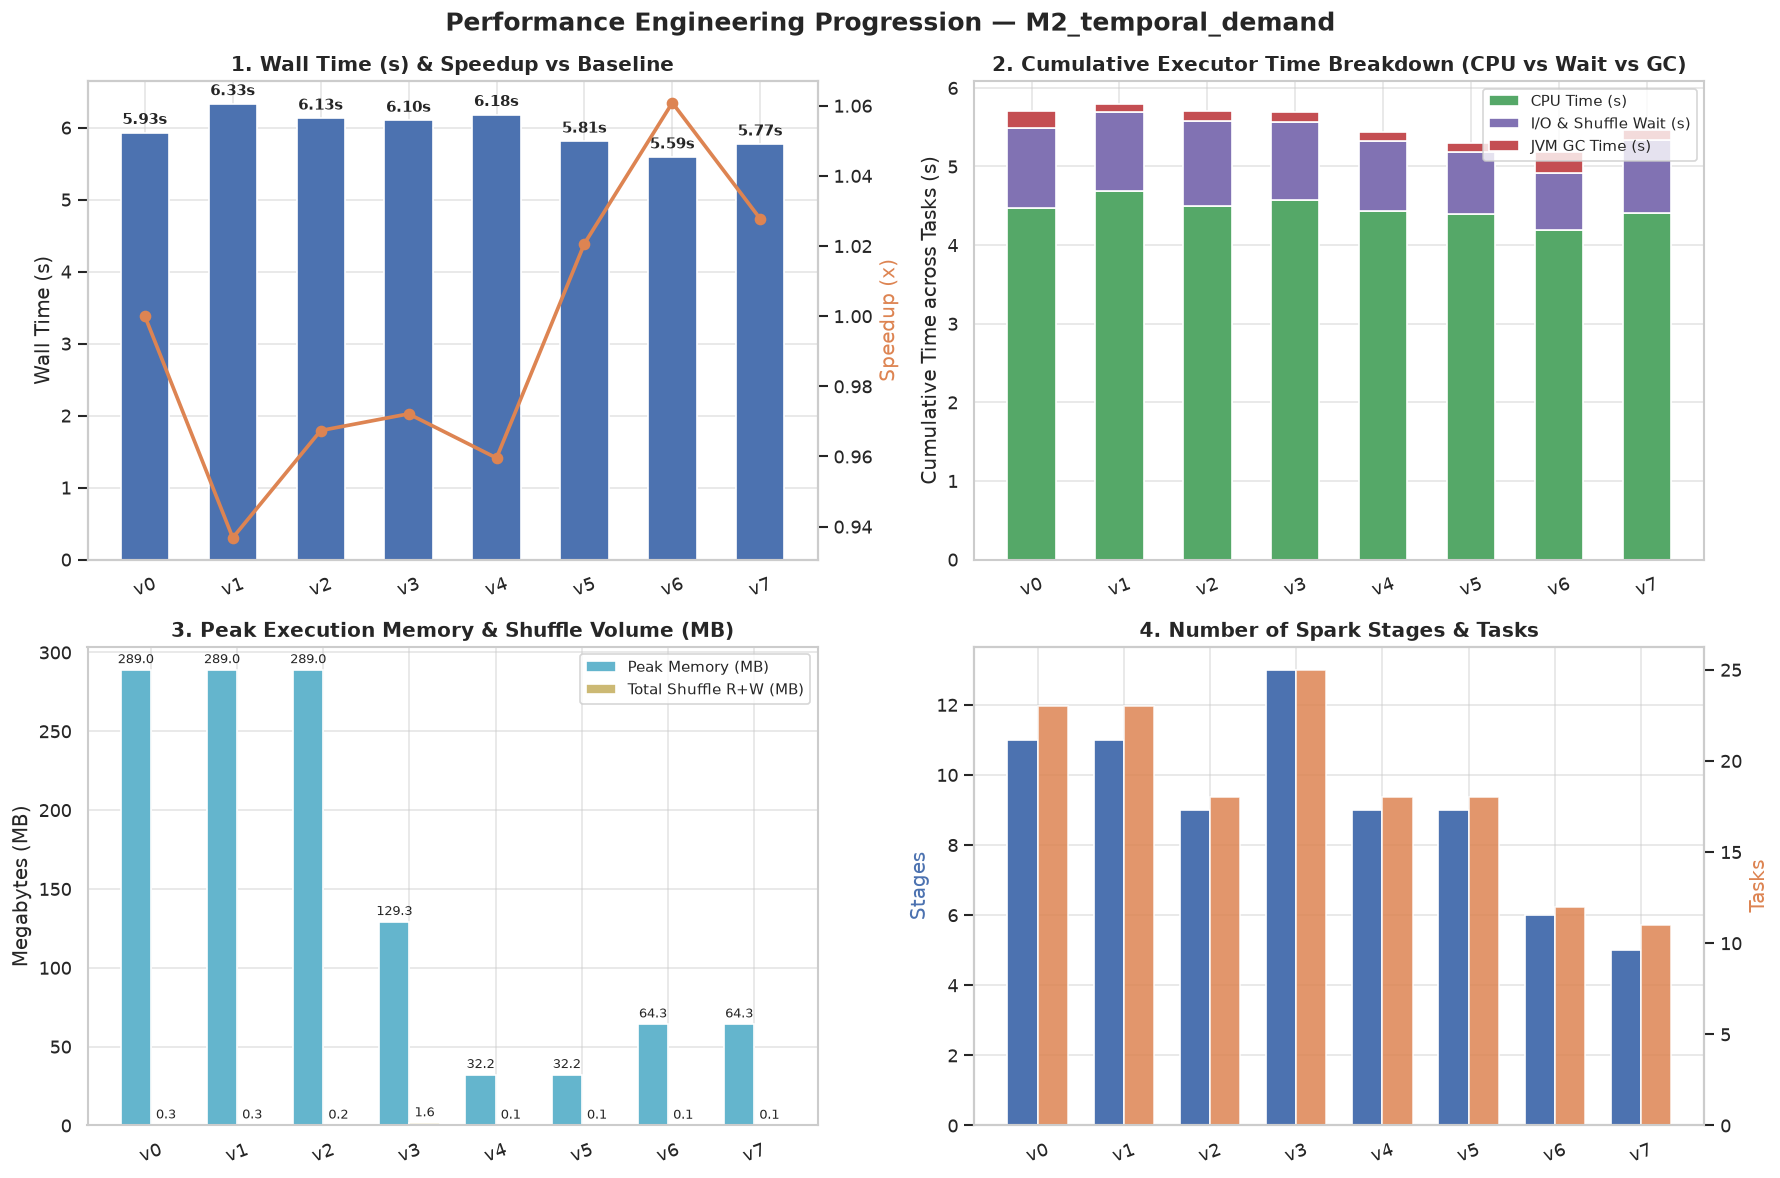

Chart saved to: ../output/plots/benchmark_M2_temporal_demand.png


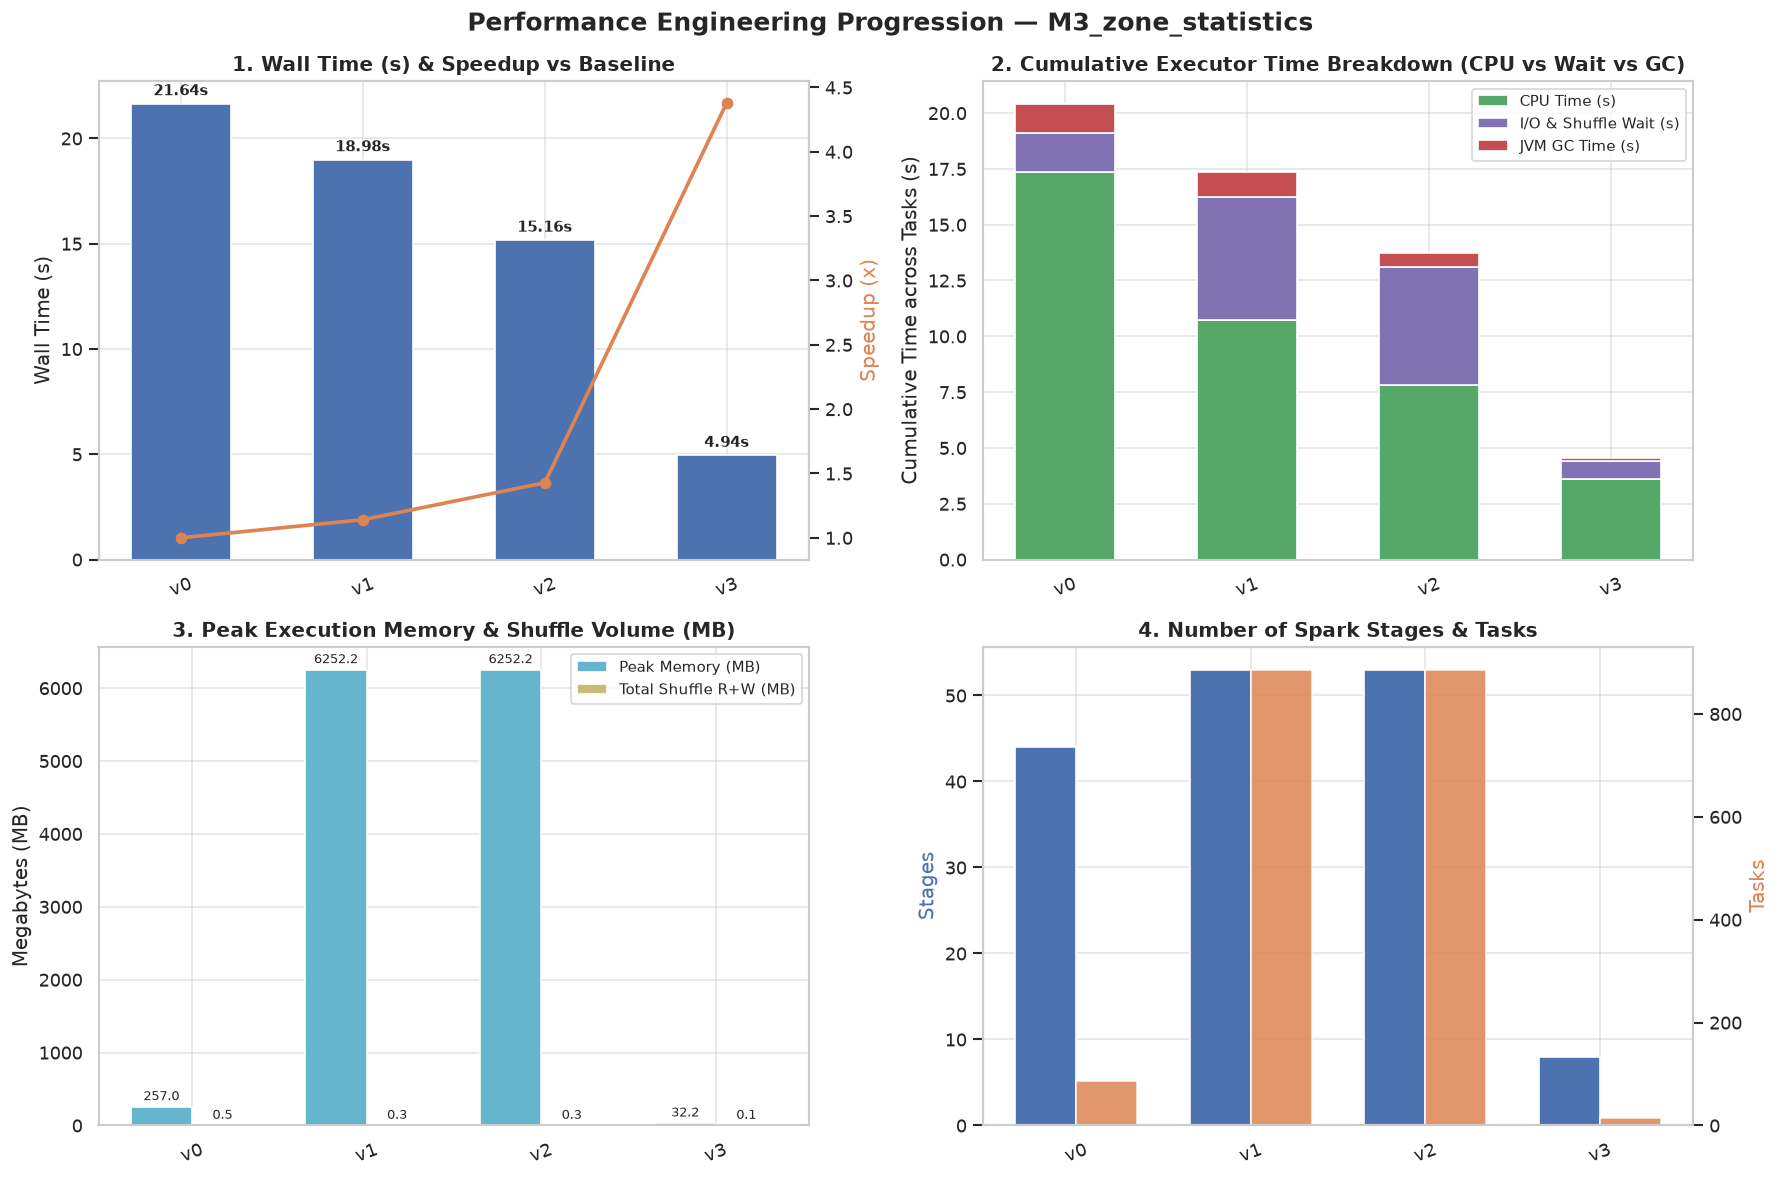

Chart saved to: ../output/plots/benchmark_M3_zone_statistics.png


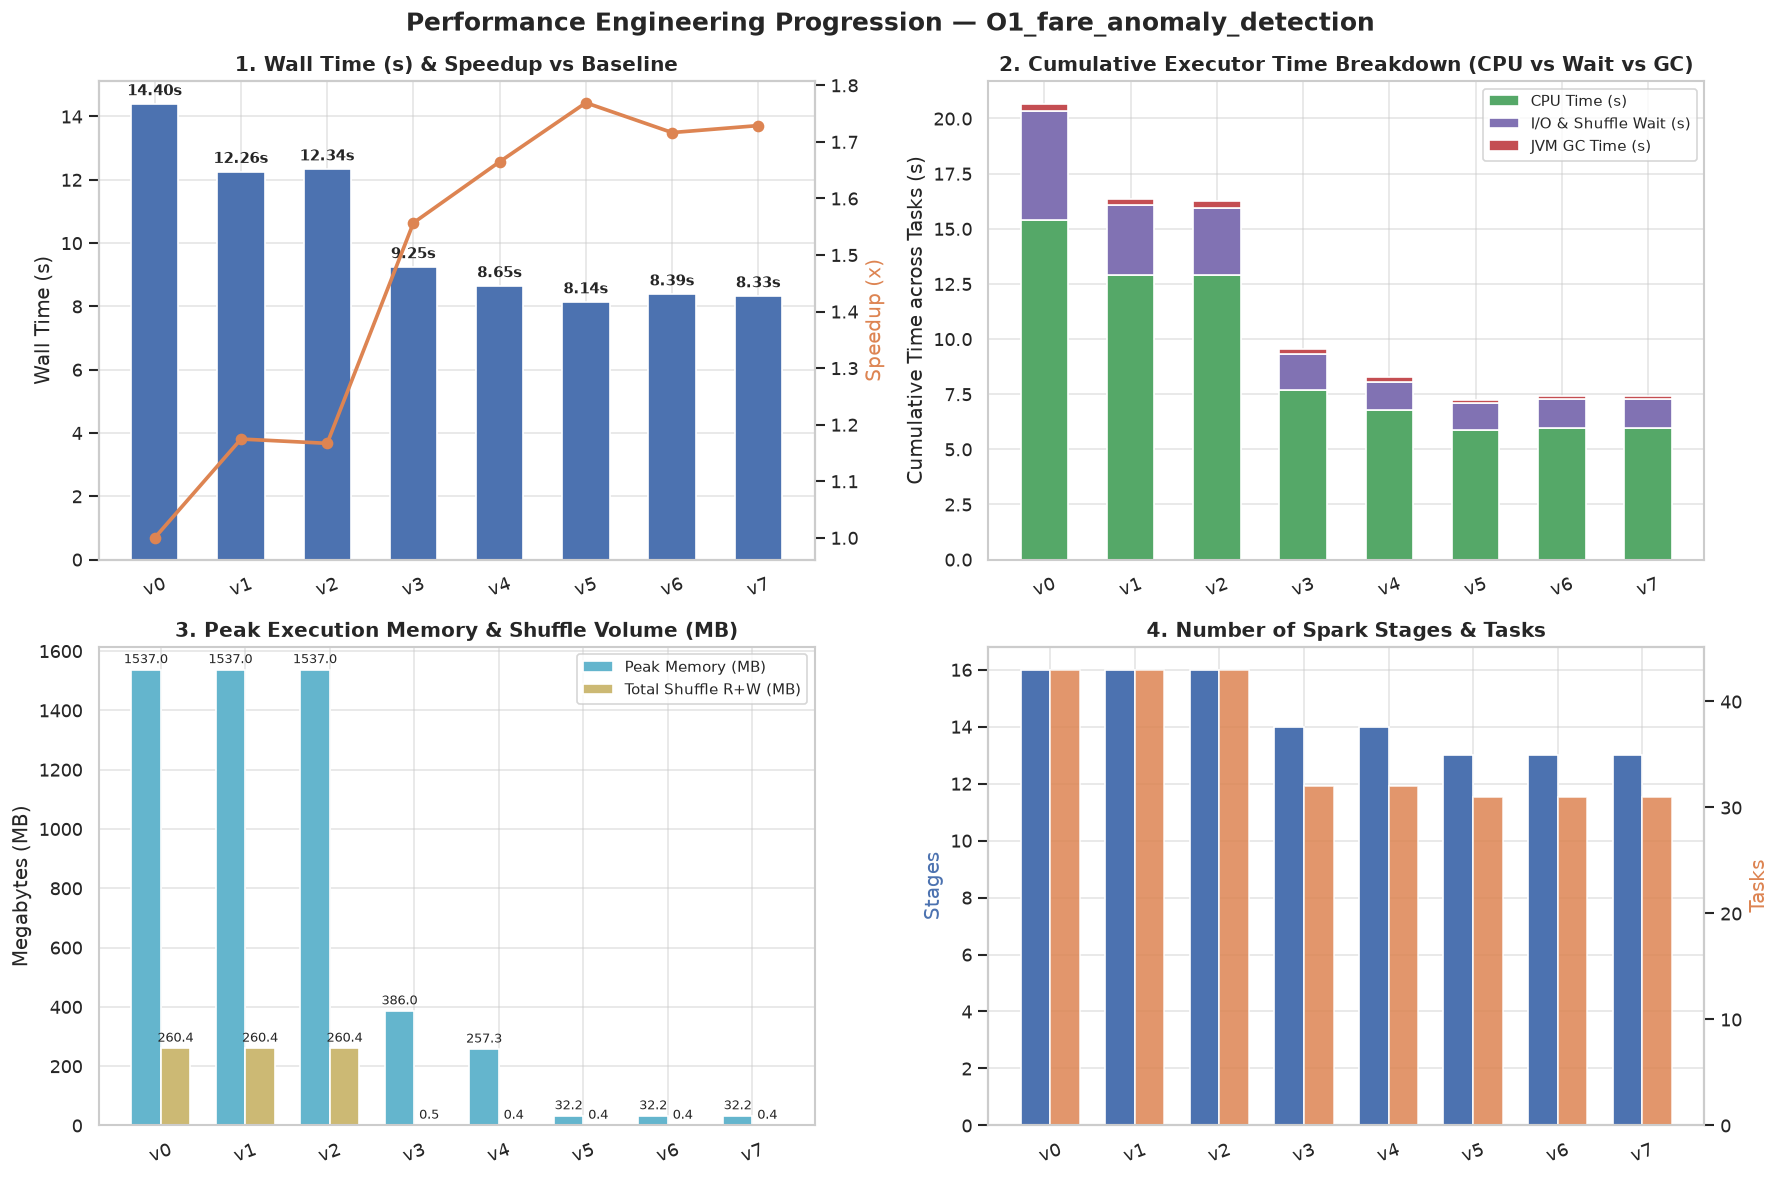

Chart saved to: ../output/plots/benchmark_O1_fare_anomaly_detection.png


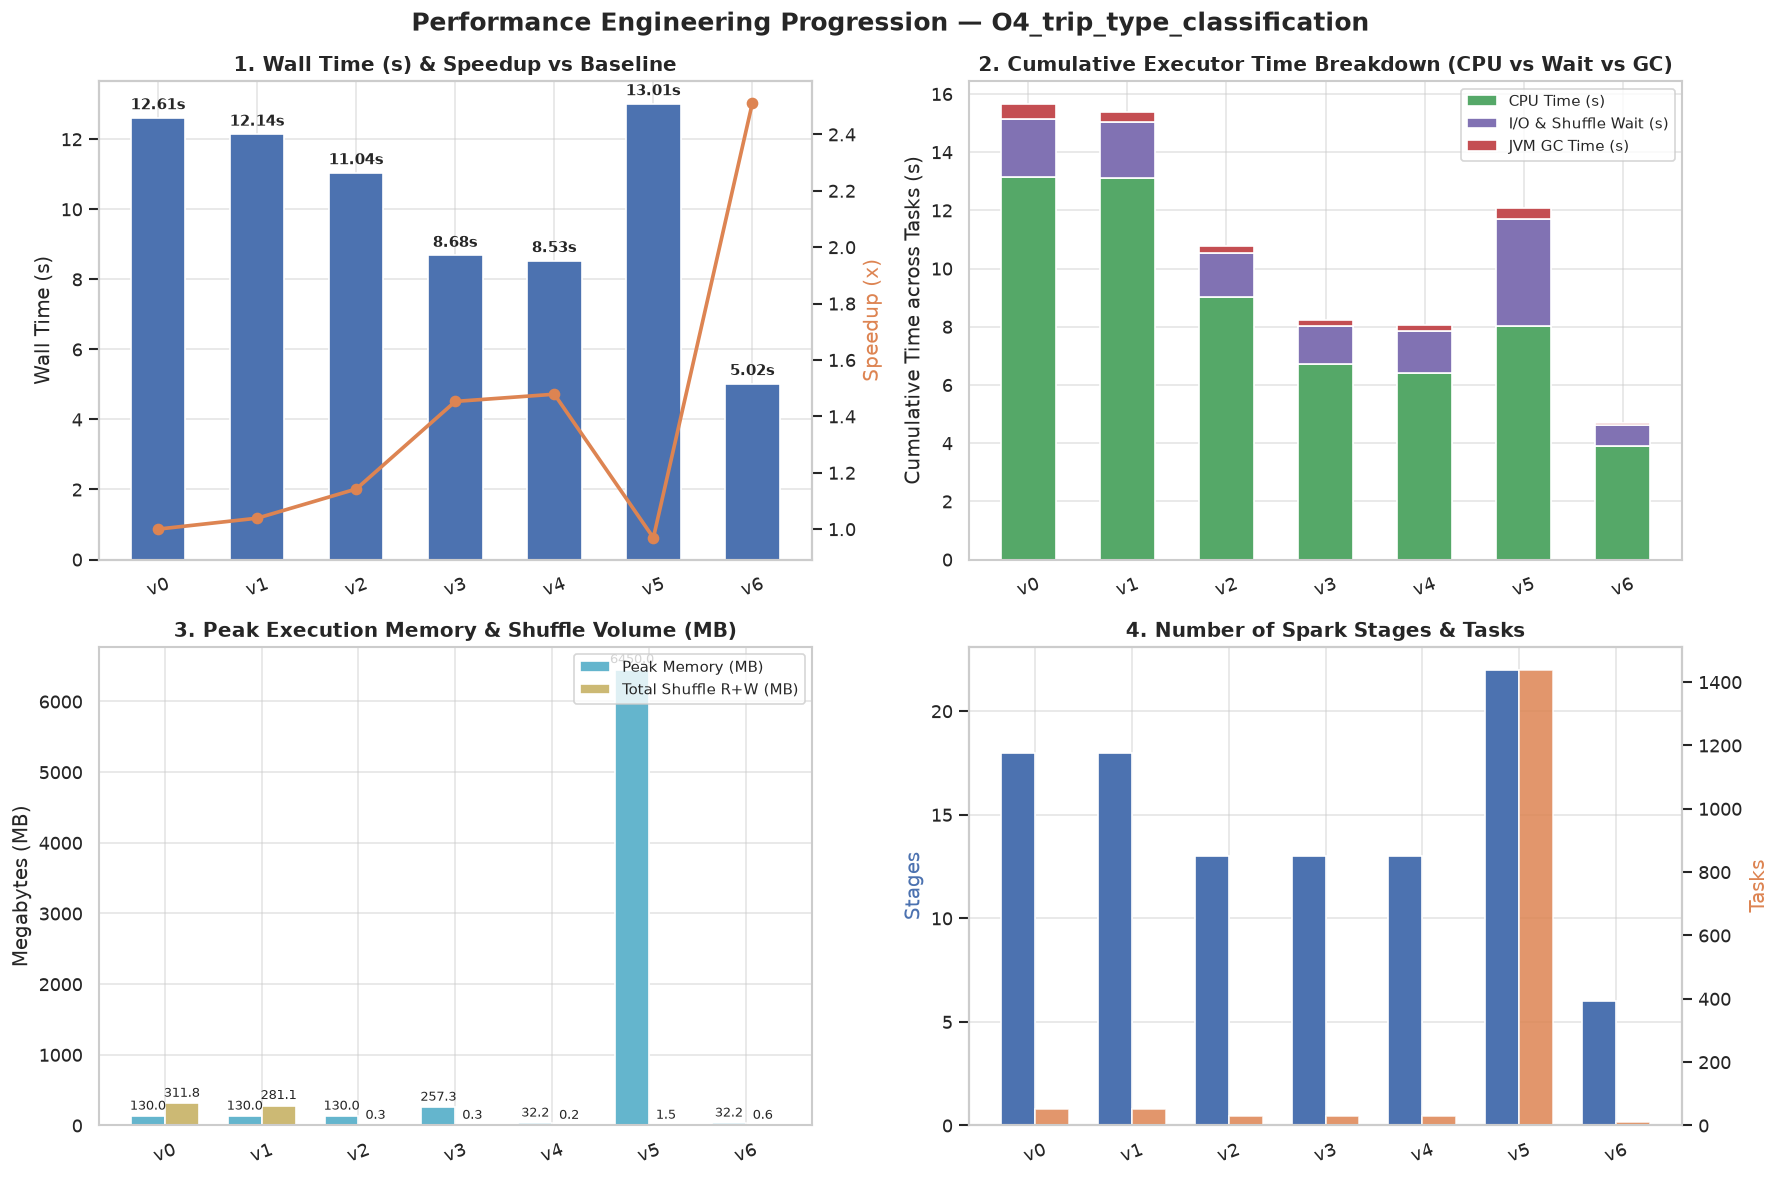

Chart saved to: ../output/plots/benchmark_O4_trip_type_classification.png


In [3]:
def plot_operation_benchmarks(df_op, op_name):
    df_op = df_op.copy().reset_index(drop=True)
    base_wall = df_op.loc[0, "wall_time_s"] if df_op.loc[0, "wall_time_s"] > 0 else 1.0
    df_op["speedup"] = base_wall / df_op["wall_time_s"].replace(0, np.nan)

    versions = df_op["version"].tolist()
    x = np.arange(len(versions))

    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle(f"Performance Engineering Progression — {op_name}", fontsize=15, fontweight="bold")

    # 1. Wall Time & Speedup
    ax1 = axes[0, 0]
    bars = ax1.bar(x, df_op["wall_time_s"], color="#4C72B0", width=0.55, label="Wall Time (s)")
    ax1.set_title("1. Wall Time (s) & Speedup vs Baseline", fontweight="bold")
    ax1.set_xticks(x)
    ax1.set_xticklabels(versions, rotation=20)
    ax1.set_ylabel("Wall Time (s)")
    for bar in bars:
        h = bar.get_height()
        ax1.annotate(f"{h:.2f}s", (bar.get_x() + bar.get_width() / 2, h),
                     ha="center", va="bottom", fontsize=9, fontweight="bold", xytext=(0, 3), textcoords="offset points")

    if len(versions) > 1:
        ax1_twin = ax1.twinx()
        ax1_twin.plot(x, df_op["speedup"], color="#DD8452", marker="o", linewidth=2.2, label="Speedup (x)")
        ax1_twin.set_ylabel("Speedup (x)", color="#DD8452")
        ax1_twin.grid(False)

    # 2. Decomposition: CPU vs GC vs I/O & Wait
    ax2 = axes[0, 1]
    ax2.bar(x, df_op["exec_cpu_s"], width=0.55, label="CPU Time (s)", color="#55A868")
    ax2.bar(x, df_op["io_wait_s"], width=0.55, bottom=df_op["exec_cpu_s"], label="I/O & Shuffle Wait (s)", color="#8172B3")
    ax2.bar(x, df_op["jvm_gc_s"], width=0.55, bottom=df_op["exec_cpu_s"] + df_op["io_wait_s"], label="JVM GC Time (s)", color="#C44E52")
    ax2.set_title("2. Cumulative Executor Time Breakdown (CPU vs Wait vs GC)", fontweight="bold")
    ax2.set_xticks(x)
    ax2.set_xticklabels(versions, rotation=20)
    ax2.set_ylabel("Cumulative Time across Tasks (s)")
    ax2.legend(loc="upper right", fontsize=9)

    # 3. Peak Execution Memory & Shuffle Volume
    ax3 = axes[1, 0]
    w = 0.35
    b1 = ax3.bar(x - w/2, df_op["peak_mem_mb"], width=w, label="Peak Memory (MB)", color="#64B5CD")
    b2 = ax3.bar(x + w/2, df_op["total_shuffle_mb"], width=w, label="Total Shuffle R+W (MB)", color="#CCB974")
    ax3.set_title("3. Peak Execution Memory & Shuffle Volume (MB)", fontweight="bold")
    ax3.set_xticks(x)
    ax3.set_xticklabels(versions, rotation=20)
    ax3.set_ylabel("Megabytes (MB)")
    ax3.legend(loc="upper right", fontsize=9)
    for bar in list(b1) + list(b2):
        h = bar.get_height()
        if h > 0:
            ax3.annotate(f"{h:.1f}", (bar.get_x() + bar.get_width() / 2, h),
                         ha="center", va="bottom", fontsize=8, xytext=(0, 2), textcoords="offset points")

    # 4. Stages & Tasks
    ax4 = axes[1, 1]
    ax4.bar(x - w/2, df_op["num_stages"], width=w, label="Stages", color="#4C72B0")
    ax4_twin = ax4.twinx()
    ax4_twin.bar(x + w/2, df_op["num_tasks"], width=w, label="Tasks", color="#DD8452", alpha=0.85)
    ax4.set_title("4. Number of Spark Stages & Tasks", fontweight="bold")
    ax4.set_xticks(x)
    ax4.set_xticklabels(versions, rotation=20)
    ax4.set_ylabel("Stages", color="#4C72B0")
    ax4_twin.set_ylabel("Tasks", color="#DD8452")
    ax4_twin.grid(False)

    plt.tight_layout()
    out_file = os.path.join(PLOTS_DIR, f"benchmark_{op_name}.png")
    plt.savefig(out_file, bbox_inches="tight")
    plt.show()
    print(f"Chart saved to: {out_file}")

if not df_runs.empty:
    for op_name, group in df_runs.groupby("operation", sort=False):
        plot_operation_benchmarks(group, op_name)


### 4. Stage Breakdown & Task Skew Diagnosis


In [4]:
if not df_stages.empty:
    stage_display = df_stages.copy()
    stage_display["skew_ratio_display"] = stage_display.apply(
        lambda r: f"{r['skew_ratio']:.1f}x (!)" if r["skew_warning"] else f"{r['skew_ratio']:.1f}x", axis=1
    )
    cols = ["version", "operation", "stage_id", "stage_name", "num_tasks",
            "run_time_ms", "cpu_time_ms", "gc_time_ms", "peak_mem_mb",
            "shuffle_read_kb", "shuffle_write_kb", "med_task_ms", "max_task_ms", "skew_ratio_display"]
    display(stage_display[cols].round(2))


,version,operation,stage_id,stage_name,num_tasks,run_time_ms,cpu_time_ms,gc_time_ms,peak_mem_mb,shuffle_read_kb,shuffle_write_kb,med_task_ms,max_task_ms,skew_ratio_display
0,v0,M1_ingestion_and_cleaning,0,M1_ingestion_and_cleaning,1,259,71,6,0.00,0.00,0.00,259,259,1.0x
1,v0,M1_ingestion_and_cleaning,1,M1_ingestion_and_cleaning,4,2169,985,88,0.00,0.00,0.22,629,648,1.0x
2,v0,M1_ingestion_and_cleaning,2,$anonfun$withThreadLocalCaptured$1 at Complet,4,0,0,0,0.00,0.00,0.00,0,0,1.0x
3,v0,M1_ingestion_and_cleaning,3,M1_ingestion_and_cleaning,1,91,63,0,0.00,0.22,0.00,91,91,1.0x
4,v0,M1_ingestion_and_cleaning,4,M1_ingestion_and_cleaning,4,4827,3525,197,1.00,0.00,0.09,465,3588,7.7x (!)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
602,v6,O4_trip_type_classification,6,O4_trip_type_classification,1,682,597,24,0.00,0.00,0.00,682,682,1.0x
603,v6,O4_trip_type_classification,7,O4_trip_type_classification,4,3681,2995,48,1.00,0.00,293.19,246,2947,12.0x (!)
604,v6,O4_trip_type_classification,8,$anonfun$withThreadLocalCaptured$1 at Complet,4,0,0,0,0.00,0.00,0.00,0,0,1.0x
605,v6,O4_trip_type_classification,9,O4_trip_type_classification,1,51,44,0,32.25,293.19,0.00,51,51,1.0x
